<div align="center">

<h1> <b> OSCILACIONES DE UN IMÁN EN UN RESORTE: MEDICIÓN DE LA FEM INDUCIDA EN UNA BOBINA </b> </h1>

</div>

<br>

<hr size=10 noshade color="green">
<p>
<p><img alt="UdeA logo" height="180px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="100px" vspace="4px"></p>

<div align="right">       

<h3><i> <b>Cristian Vergara <br>
Juan Palacio <br>
Sofía Moscoso <br>
Francisco Gonzales</b> <br>  
Universidad de Antioquia <br>
Instituto de Física  <br>
</i></h3>
</div>


---

## Introducción y objetivo

Un imán sujeto a un resorte oscila verticalmente sobre una bobina. Mientras se mueve, el flujo magnético a través de la bobina cambia y, según la ley de Faraday, entre sus terminales aparece una fuerza electromotriz (fem). Un ESP32 digitaliza esa tensión con su conversor analógico-digital (ADC) y la envía por el puerto serie a un computador.

Este notebook explica y comprueba el método con el que `spring_magnet_analyzer.py` extrae información de ese registro:

1. la frecuencia de oscilación $f_0$, a partir del espectro;
2. el coeficiente de amortiguamiento $\gamma$, a partir del decaimiento de los pulsos;
3. el campo magnético medio $B$ sobre la bobina, a partir de la integral de la fem;
4. con los datos del montaje que se conozcan, la constante $k$ del resorte y el coeficiente de amortiguamiento $b$.

No se conservan los datos medidos con el montaje físico. Por eso el método se aplica a un registro simulado con un modelo físico del experimento: al conocer los valores verdaderos se puede medir cuánto se acerca el análisis a ellos y dónde falla. El notebook se ejecuta completo sin hardware. El programa y su manual de uso están en la carpeta superior.

## Fundamentos físicos

**Inducción electromagnética.** Para una bobina de $N$ vueltas atravesadas por un flujo magnético $\Phi$, la ley de Faraday establece (Griffiths, 2017)

$$\varepsilon(t) = -N\,\frac{d\Phi}{dt}.$$

Al integrar en el tiempo, $\int_{t_1}^{t_2}\varepsilon\,dt = -N\,[\Phi(t_2)-\Phi(t_1)]$. Si $t_1$ y $t_2$ son los extremos de un lóbulo de la señal, instantes en los que $\varepsilon=0$ y por tanto $\Phi$ es extremo, la integral del lóbulo es $N$ veces el cambio de flujo entre dos extremos consecutivos. Con la aproximación de campo uniforme sobre el área $A=\pi R^2$ de la bobina, $\Delta\Phi \approx B A$ y el campo medio equivalente es

$$B \approx \frac{\left|\int \varepsilon\,dt\right|}{N A}.$$

**Oscilación amortiguada.** Un oscilador con amortiguamiento viscoso lineal, $m\ddot{x}+b\dot{x}+kx=0$, cumple en régimen subamortiguado (Taylor, 2005, sec. 5.4)

$$x(t)=A_0\,e^{-\gamma t}\cos(\omega_1 t-\delta),\qquad \gamma=\frac{b}{2m},\qquad \omega_1=\sqrt{\omega_0^2-\gamma^2},\qquad \omega_0=\sqrt{k/m}.$$

Con $\omega_1 = 2\pi f_0$ y $\gamma$ medidas, $\omega_0^2 = \omega_1^2+\gamma^2$. Las relaciones $k = m\omega_0^2$ y $b = 2m\gamma$ muestran que basta conocer una de las tres magnitudes $m$, $k$, $b$ para obtener las otras dos.

La fem es proporcional a la velocidad del imán, $\varepsilon=-N\,\Phi'(x)\,\dot{x}$. Si la altura de los pulsos (o el área de los lóbulos) fuera proporcional a la amplitud de oscilación, $\ln A$ sería lineal en $t$ con pendiente $-\gamma$. La sección 10 muestra hasta qué punto se cumple esa proporcionalidad. La medición no distingue las fuentes de pérdida: $\gamma$ incluye la resistencia del aire, la fricción interna del resorte y cualquier frenado por corrientes inducidas.

**Digitalización.** El ADC de 12 bits del ESP32 entrega cuentas entre 0 y 4095, que se convierten a tensión con un factor $V_\text{scale}$ en voltios por cuenta. Ese ADC no mide tensiones negativas: toda tensión por debajo de 0 V se lee como 0, así que de cada ciclo se registra un solo lóbulo, el de polaridad positiva.

## 1. Librerías y parámetros

El análisis usa NumPy, SciPy y Matplotlib (Harris et al., 2020; Virtanen et al., 2020; Hunter, 2007). Las constantes de la primera celda son las del programa `spring_magnet_analyzer.py`; el comentario de cada una indica qué controla. La segunda celda fija el factor de conversión del ADC y los datos del montaje que se suponen conocidos, en unidades SI.

In [1]:
import math
from dataclasses import dataclass
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import mu_0
from scipy.fft import next_fast_len, rfft, rfftfreq
from scipy.integrate import trapezoid
from scipy.signal import find_peaks, hilbert, medfilt, windows
from scipy.stats import linregress

In [2]:
ADC_MAX = 4095                # Fondo de escala del ADC de 12 bits (cuentas)
V_REF_NOMINAL = 3.3           # V. Tensión de referencia nominal del ADC
F_MIN = 0.2                   # Hz. Frecuencia mínima para buscar el pico del espectro
FACTOR_RELLENO = 8            # Relleno de ceros de la FFT: afina la resolución en frecuencia
KERNEL_MEDIANO = 101          # Muestras (impar) del filtro mediano de la envolvente
FRAC_DISTANCIA = 0.85         # Distancia mínima entre picos, en fracción del periodo 1/f0
FRAC_PROMINENCIA = 0.04       # Prominencia mínima de un pico, en fracción del máximo de la envolvente
UMBRAL_SIGMA = 2.5            # Rechazo de valores atípicos en el ajuste de ln A frente a t
MAX_ITER_AJUSTE = 4           # Iteraciones máximas de ese rechazo
MIN_LOBULOS_AREA = 6          # Lóbulos mínimos para estimar gamma a partir de sus áreas
FRAC_AREA_MIN = 0.05          # Se ignoran lóbulos con menos de esta fracción del área máxima
CICLOS_MINIMOS = 5            # Ciclos mínimos que debe contener el registro
PICO_ESPECTRAL_MIN = 10.0     # Cociente mínimo pico / mediana del espectro para aceptar una oscilación
UMBRAL_DISCREPANCIA = 0.10    # Tolerancia del cociente gamma(altura) / gamma(área)
ANCHO_RELATIVO_MIN = 0.75     # Duración mínima del lóbulo, en fracción del medio periodo
UMBRAL_SUBARMONICO = 0.15     # Amplitud relativa en f0/2 a partir de la cual se avisa
TOLERANCIA_CHEQUEO = 0.10     # Diferencia relativa a partir de la cual dos valores "no concuerdan"


class ErrorAnalisis(Exception):
    """Error que se explica al usuario sin mostrar el traceback."""


@dataclass
class Montaje:
    """Datos del montaje que el usuario conoce, en unidades SI. None significa que no se conoce."""
    vueltas: Optional[float] = None        # Vueltas de la bobina
    radio: Optional[float] = None          # m. Radio de la bobina
    masa: Optional[float] = None           # kg. Masa que oscila (imán y soporte)
    masa_resorte: Optional[float] = None   # kg
    k: Optional[float] = None              # N/m. Constante del resorte
    b: Optional[float] = None              # kg/s. Coeficiente de amortiguamiento


@dataclass
class OpcionesAnalisis:
    """Parámetros del análisis; los valores por defecto son los validados con registros simulados."""
    f_min: float = F_MIN                    # Hz
    kernel_mediano: int = KERNEL_MEDIANO    # Muestras
    umbral_sigma: float = UMBRAL_SIGMA
    frac_prominencia: float = FRAC_PROMINENCIA

In [3]:
V_SCALE = V_REF_NOMINAL / ADC_MAX   # V por cuenta (valor nominal)
MONTAJE = Montaje(vueltas=3400, radio=0.0415, masa=0.200)   # Datos del montaje que se suponen conocidos (SI)

## 2. Registro simulado

El simulador reproduce el experimento con un modelo físico simple y guarda los valores verdaderos, para poder compararlos con el resultado del análisis.

**Oscilador.** El cuerpo de masa $m$, unido a un resorte de constante $k$ con amortiguamiento viscoso $b$, se suelta desde el reposo a una distancia `amplitud` por encima de su equilibrio. Con $\gamma = b/(2m)$ y $\omega_1 = \sqrt{\omega_0^2-\gamma^2}$, la posición respecto al equilibrio es

$$x(t) = A_0 e^{-\gamma t}\left[\cos\omega_1 t + \frac{\gamma}{\omega_1}\sin\omega_1 t\right],$$

y la velocidad se anula exactamente en $t_j = j\pi/\omega_1$. Esos son los puntos de retorno del movimiento.

**Flujo.** El imán se trata como un dipolo magnético $p$ sobre el eje de la bobina, a una distancia $d = z_\text{eq} + x$ de su plano. Por reciprocidad, el flujo del dipolo a través de una espira de radio $R$ es el momento $p$ por el campo que crea esa espira, con una unidad de corriente, en la posición del dipolo (Griffiths, 2017):

$$\Phi(d) = \frac{\mu_0\,p\,R^2}{2\,(R^2+d^2)^{3/2}}.$$

La fem es $\varepsilon = -N\,\Phi'(d)\,\dot{x}$, y el momento $p$ se fija para que el pico sea de 250 mV. Como $\Phi'(d)$ no se anula para $d>0$, $\varepsilon$ solo se anula donde $\dot{x}=0$: cada lóbulo va de un punto de retorno al siguiente y su integral vale exactamente $N\,|\Phi(d_1)-\Phi(d_2)|$, con $d_1$ y $d_2$ las distancias en esos puntos. Ese es el valor verdadero con el que se compara el análisis.

**ADC.** A la tensión se le suma ruido gaussiano y dos interferencias de tres muestras en instantes aleatorios, se convierte a cuentas de 12 bits con $V_\text{scale} = 3.3\,\text{V}/4095$ y se recortan las tensiones negativas a 0. Opcionalmente se añade un desplazamiento de la señal y una zona muerta, es decir, un umbral por debajo del cual el ADC lee 0.

In [4]:
def simular_registro(m=0.200, k=16.6, b=0.0088, vueltas=3400, radio=0.0415, altura=0.035, amplitud=0.012,
                     pico_V=0.25, fs=1000.0, n_muestras=40000, ruido_V=5e-4, n_espurios=2, offset_V=0.0,
                     zona_muerta_V=0.0, t_inicio=0.0, v_ref=V_REF_NOMINAL, semilla=1):
    """Simula el registro que entregaría el ADC del ESP32 y devuelve también los valores verdaderos.

    Modelo: el cuerpo de masa m, unido a un resorte de constante k y amortiguamiento viscoso b, se suelta desde
    el reposo en x = amplitud por encima de su posición de equilibrio, que está a `altura` sobre el plano de la
    bobina. El imán se trata como un dipolo magnético sobre el eje de la bobina, de modo que el flujo por vuelta
    es Phi(d) = mu0 p R^2 / (2 (R^2 + d^2)^(3/2)) a la distancia d, y la fem es -N dPhi/dt. El momento dipolar p
    se ajusta para que el pico de la fem sea `pico_V`.

    El ADC se modela como lineal, de 12 bits, con ruido gaussiano, `offset_V` (desplazamiento de la señal) y una
    zona muerta opcional: las tensiones por debajo de `zona_muerta_V` se leen como cero y el resto se desplaza
    esa cantidad. Las tensiones negativas se leen como cero.

    Parámetros
    ----------
    m, k, b : float
        Masa (kg), constante del resorte (N/m) y coeficiente de amortiguamiento (kg/s).
    vueltas, radio : float
        Vueltas y radio (m) de la bobina.
    altura, amplitud : float
        Altura del equilibrio sobre la bobina (m) y amplitud inicial (m).
    pico_V : float
        Pico de la fem (V).
    fs, n_muestras : float, int
        Frecuencia de muestreo (Hz) y número de muestras.
    ruido_V : float
        Desviación típica del ruido (V).
    n_espurios : int
        Picos de interferencia de tres muestras añadidos en posiciones aleatorias.
    offset_V, zona_muerta_V : float
        Desplazamiento de la señal y zona muerta del ADC (V).
    t_inicio : float
        Instante, contado desde que se suelta el cuerpo, en el que empieza el registro (s).
    v_ref : float
        Tensión de referencia del ADC (V).
    semilla : int
        Semilla del generador aleatorio.

    Devuelve
    --------
    t_sec, voltajes, fs, verdad
        Instantes (s), cuentas del ADC, frecuencia de muestreo (Hz) y diccionario con los valores verdaderos.
    """
    w0 = math.sqrt(k / m)
    gamma = b / (2.0 * m)
    if gamma >= w0:
        raise ErrorAnalisis("El simulador necesita un sistema subamortiguado (b < 2*sqrt(k*m)).")
    w1 = math.sqrt(w0 ** 2 - gamma ** 2)
    rng = np.random.default_rng(semilla)

    t_rec = np.arange(n_muestras) / fs
    t = t_inicio + t_rec
    envolvente = amplitud * np.exp(-gamma * t)
    x = envolvente * (np.cos(w1 * t) + (gamma / w1) * np.sin(w1 * t))
    v = -envolvente * (w0 ** 2 / w1) * np.sin(w1 * t)
    d = altura + x

    def flujo(dist, momento):
        return momento * mu_0 * radio ** 2 / (2.0 * (radio ** 2 + dist ** 2) ** 1.5)

    base = 3.0 * vueltas * (mu_0 * radio ** 2 / 2.0) * d * (radio ** 2 + d ** 2) ** -2.5 * v   # fem por A*m^2
    momento = pico_V / base.max()
    fem = momento * base

    v_scale = v_ref / ADC_MAX
    tension = fem + offset_V + rng.normal(0.0, ruido_V, n_muestras)
    for pos in rng.integers(int(0.1 * n_muestras), int(0.9 * n_muestras), size=n_espurios):
        tension[pos:pos + 3] += 0.4 * pico_V
    leida = np.maximum(tension - zona_muerta_V, 0.0)
    cuentas = np.clip(np.rint(leida / v_scale), 0, ADC_MAX)

    # Valores verdaderos: los lóbulos de la fem van entre dos puntos de retorno consecutivos, t_j = j*pi/w1
    area_espira = math.pi * radio ** 2
    lobulos = []
    j = 0
    while (j + 1) * math.pi / w1 <= t_inicio + t_rec[-1]:
        t_a, t_b = j * math.pi / w1, (j + 1) * math.pi / w1
        if t_a >= t_inicio:
            pos_a = altura + amplitud * math.exp(-gamma * t_a) * (-1) ** j
            pos_b = altura + amplitud * math.exp(-gamma * t_b) * (-1) ** (j + 1)
            integral = abs(vueltas * (flujo(pos_b, momento) - flujo(pos_a, momento)))
            positivo = (j % 2 == 1)   # el ascenso da fem positiva
            if positivo or offset_V != 0.0:
                lobulos.append(integral)
        j += 1
    integral_verdadera = max(lobulos)
    verdad = {
        "masa_kg": m, "k_N_m": k, "b_kg_s": b, "gamma_1_s": gamma, "omega0_rad_s": w0, "omega1_rad_s": w1,
        "f0_Hz": w1 / (2.0 * math.pi), "Q": w0 / (2.0 * gamma), "vueltas": vueltas, "radio_m": radio,
        "integral_emf_Vs": integral_verdadera, "B_T": integral_verdadera / (vueltas * area_espira),
        "momento_dipolar_Am2": momento, "altura_m": altura, "amplitud_m": amplitud,
        "V_scale_V_per_count": v_scale, "zona_muerta_V": zona_muerta_V, "offset_V": offset_V,
    }
    return t_rec, cuentas, float(fs), verdad

In [5]:
t_sec, voltajes, fs, verdad = simular_registro()
N = len(voltajes)
print(f"Registro simulado: {N} muestras, {N / fs:.0f} s, fs = {fs:.0f} Hz, pico de la fem de 250 mV")
print(f"Valores verdaderos: f0 = {verdad['f0_Hz']:.4f} Hz, gamma = {verdad['gamma_1_s']:.4f} 1/s, "
      f"k = {verdad['k_N_m']:.1f} N/m, b = {verdad['b_kg_s']:.4f} kg/s")
print(f"Lóbulo mayor: integral de la fem = {verdad['integral_emf_Vs']:.5f} V*s, B = {verdad['B_T'] * 1e3:.4f} mT")

Registro simulado: 40000 muestras, 40 s, fs = 1000 Hz, pico de la fem de 250 mV
Valores verdaderos: f0 = 1.4500 Hz, gamma = 0.0220 1/s, k = 16.6 N/m, b = 0.0088 kg/s
Lóbulo mayor: integral de la fem = 0.05157 V*s, B = 2.8035 mT


## 3. Preprocesado

El ADC entrega cuentas enteras entre 0 y 4095. El preprocesado hace tres cosas.

1. Las lecturas ilegibles (NaN) se reemplazan por interpolación lineal. En un registro real aparecen cuando una línea del puerto serie llega corrupta.
2. Se toma como nivel de reposo la mediana de las cuentas y se expresa la señal en voltios respecto a él, $v = (\text{cuentas}-\text{reposo})\,V_\text{scale}$. Como el ADC recorta las tensiones negativas, la señal es un tren de pulsos unipolares y su media no es el nivel de fem nula, pero la mediana sí lo es mientras los pulsos ocupen menos de la mitad del tiempo. Restar la media haría parecer más bajos los pulsos y subestimaría sus integrales.
3. Para el análisis espectral se usa la misma señal con media cero, porque la componente continua no informa sobre la frecuencia.

In [6]:
def preparar_senal(t_sec, voltajes, v_scale):
    """Interpola las lecturas ilegibles y expresa la señal en voltios respecto al nivel de reposo.

    El ADC recorta las tensiones negativas, así que la señal es un tren de pulsos unipolares y su media no es
    el nivel de fem nula. Mientras los pulsos ocupen menos de la mitad del tiempo, la mediana sí lo es.

    Devuelve un diccionario con
        v : señal en V respecto al reposo (para amplitudes e integrales)
        proc : la misma señal con media cero (para el espectro)
        interp, reposo : cuentas con los NaN interpolados y nivel de reposo en cuentas
        valid : máscara de las lecturas legibles
        advertencias : lista de textos
    """
    voltajes = np.asarray(voltajes, dtype=float)
    n = len(voltajes)
    valid = np.isfinite(voltajes)
    n_validas = int(np.count_nonzero(valid))
    if n_validas < 100:
        raise ErrorAnalisis("Hay menos de 100 muestras legibles: no se puede analizar el registro.")
    advertencias = []
    if n_validas < 0.99 * n:
        advertencias.append(f"Se interpolaron {n - n_validas} de {n} muestras ({100 * (n - n_validas) / n:.1f} %).")
    interp = np.interp(t_sec, t_sec[valid], voltajes[valid])
    if np.any(interp >= ADC_MAX):
        advertencias.append("Hay lecturas en el fondo de escala del ADC (saturación): amplitudes e integrales "
                            "quedan subestimadas.")
    reposo = float(np.median(interp))
    v = (interp - reposo) * v_scale
    if np.mean(np.abs(v) > v_scale) >= 0.5:
        advertencias.append("La señal está activa más de la mitad del tiempo: la mediana ya no es el nivel de "
                            "reposo y las amplitudes pueden estar sesgadas.")
    return {"v": v, "proc": v - v.mean(), "interp": interp, "reposo": reposo, "valid": valid,
            "advertencias": advertencias, "n_interpoladas": n - n_validas}

In [7]:
prep = preparar_senal(t_sec, voltajes, V_SCALE)
v, v_proc = prep["v"], prep["proc"]
print(f"Nivel de reposo: {prep['reposo']:.1f} cuentas; muestras interpoladas: {prep['n_interpoladas']}")
print("Advertencias:", prep["advertencias"] or "ninguna")

Nivel de reposo: 0.0 cuentas; muestras interpoladas: 0
Advertencias: ninguna


## 4. Inspección de la señal

Antes de analizar se comprueba que el registro tenga la estructura esperada: pulsos positivos periódicos de amplitud decreciente, sin saturación del ADC y sin tramos interpolados extensos. La figura inferior amplía los primeros pulsos. Las dos interferencias aparecen como picos aislados.

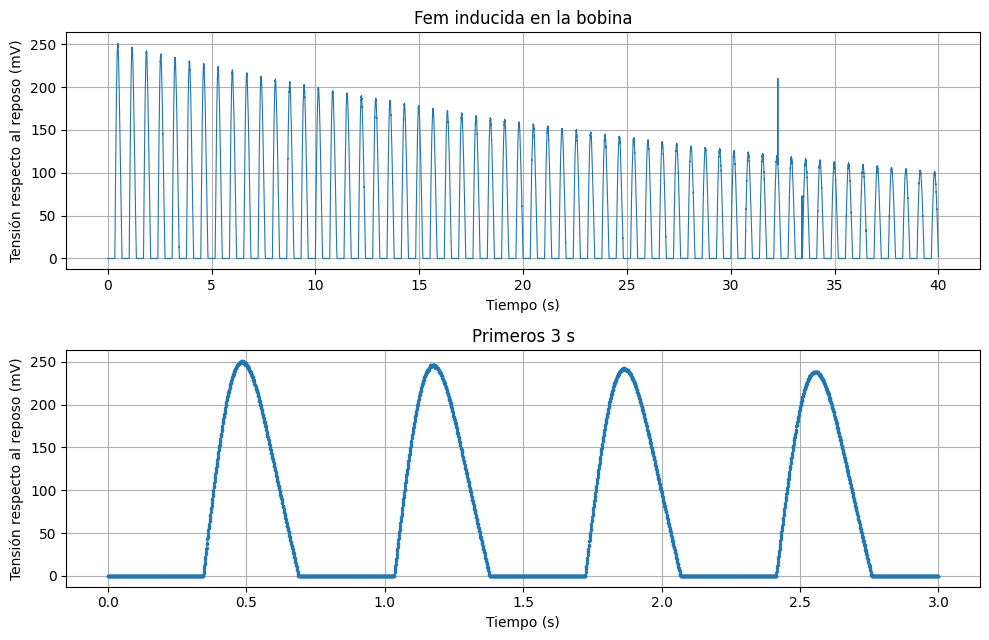

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5))
ax1.plot(t_sec, v * 1e3, lw=0.8)
ax1.set(xlabel="Tiempo (s)", ylabel="Tensión respecto al reposo (mV)", title="Fem inducida en la bobina")
ax1.grid(True)
zoom = t_sec <= 3.0
ax2.plot(t_sec[zoom], v[zoom] * 1e3, ".-", ms=3, lw=0.6)
ax2.set(xlabel="Tiempo (s)", ylabel="Tensión respecto al reposo (mV)", title="Primeros 3 s")
ax2.grid(True)
fig.tight_layout()
plt.show()

## 5. Frecuencia dominante

La frecuencia dominante se obtiene del espectro de amplitud de la señal de media cero, multiplicada por una ventana de Hann para reducir la fuga espectral (Harris, 1978). Se rellena con ceros hasta ocho veces su longitud, lo que no cambia el ancho físico de la línea pero muestrea el espectro con una resolución ocho veces mejor que $1/T$. La frecuencia $f_0$ es el máximo para $f \geq f_\text{mín}$, y su incertidumbre es la mitad del ancho a media amplitud (FWHM) de la línea. Con la ventana de Hann ese ancho vale $2/T$ incluso para una sinusoide pura, por lo que $\sigma_f$ es una cota conservadora del error de $f_0$.

El tren de pulsos no es sinusoidal, así que el espectro tiene armónicos en $2f_0$, $3f_0$ y siguientes. Si el máximo cayera en un armónico, $f_0$ saldría múltiplo de la frecuencia real; la función avisa cuando hay un pico en $f_0/2$ con amplitud apreciable. Si cada ciclo produce un solo pulso positivo, $f_0$ es la frecuencia de oscilación del imán.

In [9]:
def frecuencia_dominante(x, fs, f_min=F_MIN, relleno=FACTOR_RELLENO):
    """Frecuencia dominante de una señal real y ancho de su pico espectral.

    Se multiplica la señal por una ventana de Hann, se calcula la FFT real con relleno de ceros y se toma el
    máximo del espectro de amplitud para f >= f_min. La incertidumbre es la mitad del ancho a media altura
    (FWHM) del pico, cuyos cruces con la media altura se obtienen por interpolación lineal.

    Parámetros
    ----------
    x : ndarray
        Señal real de media cero, en cualquier unidad.
    fs : float
        Frecuencia de muestreo, Hz.
    f_min : float
        Frecuencia mínima, Hz, desde la que se busca el máximo.
    relleno : int
        Factor de relleno de ceros; no cambia el ancho físico de la línea, solo muestrea mejor el espectro.

    Devuelve
    --------
    dict con
        f0, sigma_f, fwhm, f_izq, f_der : Hz (frecuencia dominante, FWHM / 2, FWHM y cruces a media altura)
        freqs : ndarray, Hz (frecuencias positivas)
        espectro : ndarray (amplitud normalizada a su máximo)
        contraste : cociente entre el pico y la mediana del espectro
        amp_subarmonico : amplitud relativa al pico en f0 / 2
    """
    n = len(x)
    n_fft = next_fast_len(n * relleno, real=True)
    amplitud = np.abs(rfft(x * windows.hann(n), n=n_fft))
    freqs = rfftfreq(n_fft, d=1.0 / fs)
    amplitud, freqs = amplitud[1:], freqs[1:]   # Se excluye f = 0
    if not amplitud.max() > 0:
        raise ErrorAnalisis("El espectro es nulo: el registro no contiene ninguna oscilación.")
    espectro = amplitud / amplitud.max()

    candidatos = np.flatnonzero(freqs >= f_min)
    if candidatos.size == 0:
        raise ErrorAnalisis("f_min supera la frecuencia máxima del espectro.")
    i_pico = candidatos[np.argmax(espectro[candidatos])]
    f0 = freqs[i_pico]
    mitad = espectro[i_pico] / 2.0

    # Último punto bajo la media altura a la izquierda del pico y primero a la derecha; se interpola entre ese
    # punto y su vecino hacia el pico. Si no hay cruce, se toma el borde del espectro.
    izq = np.flatnonzero(espectro[:i_pico] <= mitad)
    if izq.size:
        j = izq[-1]
        f_izq = np.interp(mitad, [espectro[j], espectro[j + 1]], [freqs[j], freqs[j + 1]])
    else:
        f_izq = freqs[0]
    der = np.flatnonzero(espectro[i_pico:] <= mitad)
    if der.size:
        j = i_pico + der[0]
        f_der = np.interp(mitad, [espectro[j], espectro[j - 1]], [freqs[j], freqs[j - 1]])
    else:
        f_der = freqs[-1]
    fwhm = f_der - f_izq

    amp_sub = 0.0
    if f0 / 2.0 >= f_min:
        cerca = np.abs(freqs - f0 / 2.0) <= max(fwhm, 2.0 * (freqs[1] - freqs[0]))
        if cerca.any():
            amp_sub = float(espectro[cerca].max() / espectro[i_pico])
    contraste = float(espectro[i_pico] / max(np.median(espectro), 1e-300))
    return {"f0": f0, "sigma_f": fwhm / 2.0, "fwhm": fwhm, "f_izq": f_izq, "f_der": f_der, "freqs": freqs,
            "espectro": espectro, "contraste": contraste, "amp_subarmonico": amp_sub}

In [10]:
esp = frecuencia_dominante(v_proc, fs)
f0 = esp["f0"]
print(f"f0 = {f0:.4f} Hz   (FWHM = {esp['fwhm']:.4f} Hz, sigma_f = {esp['sigma_f']:.4f} Hz)")
print(f"Contraste del pico: {esp['contraste']:.0f}; amplitud relativa en f0/2: {esp['amp_subarmonico']:.3f}")
print(f"Valor verdadero: {verdad['f0_Hz']:.4f} Hz (diferencia {100 * (f0 - verdad['f0_Hz']) / verdad['f0_Hz']:+.3f} %)")

f0 = 1.4500 Hz   (FWHM = 0.0503 Hz, sigma_f = 0.0251 Hz)
Contraste del pico: 12836; amplitud relativa en f0/2: 0.000
Valor verdadero: 1.4500 Hz (diferencia +0.002 %)


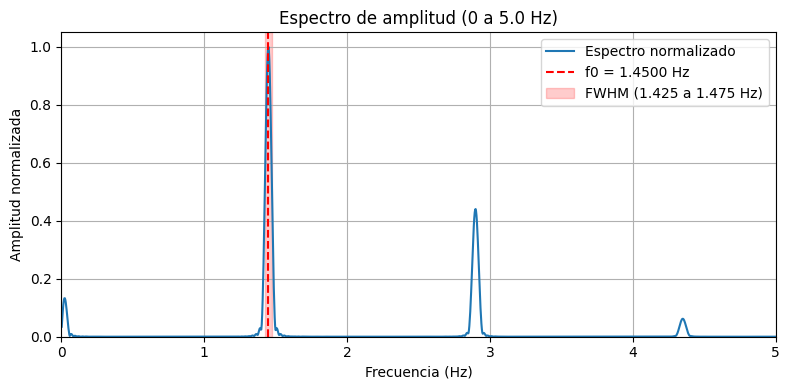

In [11]:
xlim_max = max(5.0, 3.0 * f0)   # Se muestran al menos los tres primeros armónicos
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(esp["freqs"], esp["espectro"], label="Espectro normalizado")
ax.axvline(f0, color="r", ls="--", label=f"f0 = {f0:.4f} Hz")
ax.axvspan(esp["f_izq"], esp["f_der"], color="r", alpha=0.2,
           label=f"FWHM ({esp['f_izq']:.3f} a {esp['f_der']:.3f} Hz)")
ax.set(xlim=(0, xlim_max), ylim=(0, 1.05), xlabel="Frecuencia (Hz)", ylabel="Amplitud normalizada",
       title=f"Espectro de amplitud (0 a {xlim_max:.1f} Hz)")
ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()

## 6. Envolvente y decaimiento de la altura de los pulsos

La envolvente es el módulo de la señal analítica, $|x + i\,\mathcal{H}\{x\}|$, calculada con la transformada de Hilbert (Marple, 1999) sobre la señal referida al reposo, de modo que la altura de cada pulso se mide respecto a la fem nula. Sobre la envolvente se aplica un filtro mediano, que elimina picos espurios más estrechos que su ventana, y se detecta un pico por ciclo: la distancia mínima entre picos es una fracción del periodo $1/f_0$ y se exige una prominencia mínima relativa al máximo.

La altura $A_k$ de cada pico se ajusta a $A(t)=A_0e^{-\gamma t}$, es decir, $\ln A_k$ es lineal en $t_k$ con pendiente $-\gamma$. El ajuste por mínimos cuadrados se repite descartando los picos cuyo residuo supera `UMBRAL_SIGMA` desviaciones típicas, hasta que el conjunto usado deja de cambiar o se alcanza `MAX_ITER_AJUSTE`, y el resultado final corresponde exactamente a los picos conservados. La incertidumbre de $\gamma$ es el error estándar de la pendiente.

In [12]:
def envolvente_y_picos(x, f0, fs, kernel=KERNEL_MEDIANO, frac_prominencia=FRAC_PROMINENCIA):
    """Envolvente de Hilbert suavizada de una señal y posiciones de sus picos (uno por ciclo).

    Parámetros
    ----------
    x : ndarray
        Señal real, referida a su nivel de fem nula para que la altura de los pulsos sea la amplitud.
    f0 : float
        Frecuencia dominante, Hz; fija la distancia mínima entre picos.
    fs : float
        Frecuencia de muestreo, Hz.
    kernel : int
        Tamaño, en muestras, de la ventana del filtro mediano (si es par se aumenta en uno).
    frac_prominencia : float
        Prominencia mínima de un pico, en fracción del máximo de la envolvente suavizada.

    Devuelve
    --------
    envelope, env_smooth : ndarray, misma unidad que x (envolvente y envolvente suavizada)
    indices_picos : ndarray de int (índices de los picos de env_smooth)
    """
    envelope = np.abs(hilbert(x))
    k = kernel if kernel % 2 == 1 else kernel + 1            # medfilt exige una ventana impar
    env_smooth = medfilt(envelope, kernel_size=k)            # Elimina picos espurios más estrechos que la ventana
    distancia = max(1, int((1.0 / f0) * fs * FRAC_DISTANCIA))   # Muestras: obliga a un solo pico por ciclo
    indices_picos, _ = find_peaks(env_smooth, distance=distancia,
                                  prominence=frac_prominencia * np.max(env_smooth))
    return envelope, env_smooth, indices_picos

In [13]:
def ajustar_decaimiento(t, A, umbral_sigma=UMBRAL_SIGMA, max_iter=MAX_ITER_AJUSTE):
    """Ajuste lineal de ln A frente a t con rechazo iterativo de valores atípicos.

    Modelo: A(t) = A0 exp(-gamma t), es decir, ln A = ln A0 - gamma t. En cada iteración se ajusta con los
    valores conservados y se descartan los que tienen un residuo mayor que umbral_sigma desviaciones típicas.
    El proceso termina cuando el conjunto no cambia o quedarían menos de tres valores, y el ajuste final se
    calcula con el conjunto conservado.

    Parámetros
    ----------
    t : ndarray, s
        Instante de cada valor.
    A : ndarray
        Valores positivos (alturas de pulsos o áreas de lóbulos).
    umbral_sigma, max_iter : float, int
        Criterio de rechazo y número máximo de iteraciones.

    Devuelve
    --------
    ajuste : resultado de scipy.stats.linregress sobre (t, ln A) con los valores conservados; gamma = -ajuste.slope
    mascara : ndarray de bool, True en los valores conservados
    """
    lnA = np.log(A)
    mascara = np.ones(lnA.shape, dtype=bool)
    for _ in range(max_iter):
        ajuste = linregress(t[mascara], lnA[mascara])
        residuos = lnA - (ajuste.intercept + ajuste.slope * t)
        sigma = np.std(residuos[mascara])
        nueva = np.abs(residuos) <= umbral_sigma * sigma   # <= para no descartar nada si el ajuste es exacto
        if np.array_equal(nueva, mascara) or np.count_nonzero(nueva) < 3:
            break
        mascara = nueva
    return linregress(t[mascara], lnA[mascara]), mascara

In [14]:
envelope, env_smooth, indices_picos = envolvente_y_picos(v, f0, fs)
t_picos, A_picos = t_sec[indices_picos], env_smooth[indices_picos]
ajuste_h, mask_h = ajustar_decaimiento(t_picos, A_picos)
gamma_h = -ajuste_h.slope
print(f"Picos detectados: {len(indices_picos)}, usados en el ajuste: {np.count_nonzero(mask_h)}")
print(f"gamma (altura de los pulsos) = {gamma_h:.5f} ± {ajuste_h.stderr:.5f} 1/s   (R2 = {ajuste_h.rvalue ** 2:.4f})")
print(f"Valor verdadero: {verdad['gamma_1_s']:.5f} 1/s (diferencia {100 * (gamma_h / verdad['gamma_1_s'] - 1):+.1f} %)")

Picos detectados: 58, usados en el ajuste: 49
gamma (altura de los pulsos) = 0.02312 ± 0.00008 1/s   (R2 = 0.9995)
Valor verdadero: 0.02200 1/s (diferencia +5.1 %)


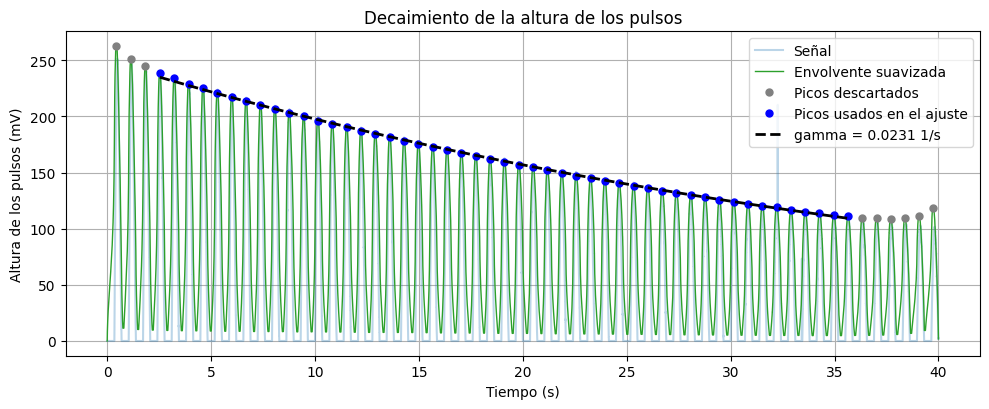

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(t_sec, v * 1e3, alpha=0.3, label="Señal")
ax.plot(t_sec, env_smooth * 1e3, color="tab:green", lw=1, label="Envolvente suavizada")
ax.plot(t_picos[~mask_h], A_picos[~mask_h] * 1e3, "o", color="gray", ms=5, label="Picos descartados")
ax.plot(t_picos[mask_h], A_picos[mask_h] * 1e3, "o", color="blue", ms=5, label="Picos usados en el ajuste")
t_curva = np.linspace(t_picos[mask_h].min(), t_picos[mask_h].max(), 300)
ax.plot(t_curva, np.exp(ajuste_h.intercept + ajuste_h.slope * t_curva) * 1e3, "k--", lw=2,
        label=f"gamma = {gamma_h:.4f} 1/s")
ax.set(xlabel="Tiempo (s)", ylabel="Altura de los pulsos (mV)", title="Decaimiento de la altura de los pulsos")
ax.legend(loc="upper right")
ax.grid(True)
fig.tight_layout()
plt.show()

## 7. Lóbulos de la fem: integral, campo magnético y decaimiento del área

Se identifican todos los lóbulos de la señal, es decir, los tramos contiguos de signo constante, y se calcula la integral de cada uno con la regla del trapecio. Se descartan los lóbulos cortados por los extremos del registro y se elige el de mayor integral en valor absoluto, que corresponde al mayor cambio de flujo registrado. Elegir por integral y no por el valor máximo de una muestra evita que una interferencia aislada decida qué lóbulo se usa.

La incertidumbre de la integral incluye solo el ruido de lectura. Para ruido blanco de desviación $\sigma_V$, la segunda diferencia de la señal tiene desviación $\sqrt{6}\,\sigma_V$, mientras que la parte suave del pulso aporta poco; con eso se estima $\sigma_V$ dentro del lóbulo, con el ruido de cuantización $V_\text{scale}/\sqrt{12}$ como mínimo. La integral de $n$ muestras independientes tiene incertidumbre $\sigma_V\sqrt{n}\,\Delta t$.

Las integrales de todos los lóbulos dan una segunda estimación de $\gamma$: si cada una es proporcional a la amplitud en el instante del lóbulo, también decaen como $e^{-\gamma t}$. Se ajustan igual que las alturas, con los lóbulos que tienen al menos el 5 % del área máxima. El programa usa esta estimación en los cálculos siguientes cuando hay al menos 6 lóbulos completos, y la de la altura como comprobación.

In [16]:
def lobulos_de_signo_constante(v, t):
    """Tramos contiguos de signo constante de una señal y su integral temporal.

    Parámetros
    ----------
    v : ndarray
        Señal (por ejemplo, tensión en V) referida a su nivel nulo.
    t : ndarray
        Instantes de las muestras (s), de igual longitud que v.

    Devuelve
    --------
    inicios, fines : ndarray de int
        Índices de la primera y la última muestra de cada tramo (ambas incluidas). Los tramos con v == 0 se omiten.
    areas : ndarray
        Integral de v sobre cada tramo con la regla del trapecio (unidad de v por segundo).
    """
    s = np.sign(v)
    cambios = np.flatnonzero(np.diff(s) != 0) + 1
    inicios = np.concatenate(([0], cambios))
    fines = np.concatenate((cambios - 1, [len(v) - 1]))
    # Integral acumulada por trapecios: el área del tramo [i, f] es C[f] - C[i]. Así se evita un bucle por tramo.
    C = np.concatenate(([0.0], np.cumsum(0.5 * (v[1:] + v[:-1]) * np.diff(t))))
    areas = C[fines] - C[inicios]
    con_senal = s[inicios] != 0
    return inicios[con_senal], fines[con_senal], areas[con_senal]


def sigma_ruido(v, sigma_min):
    """Desviación típica del ruido blanco superpuesto a una señal suave.

    Para ruido blanco de desviación sigma, la segunda diferencia d2[i] = v[i+1] - 2 v[i] + v[i-1] tiene
    desviación sqrt(6) sigma, mientras que la parte suave de la señal aporta poco. Se usa la desviación absoluta
    mediana de d2 porque no se ve afectada por las pocas muestras donde la curvatura es mayor.

    Parámetros
    ----------
    v : ndarray
        Señal en cualquier unidad.
    sigma_min : float
        Cota inferior en la misma unidad: el ruido de cuantización del ADC, V_scale / sqrt(12).

    Devuelve
    --------
    float, en la unidad de v.
    """
    d2 = v[2:] - 2.0 * v[1:-1] + v[:-2]
    mad = np.median(np.abs(d2 - np.median(d2)))
    return max(1.4826 * mad / np.sqrt(6.0), sigma_min)

In [17]:
ini, fin, areas = lobulos_de_signo_constante(v, t_sec)
completos = (ini > 0) & (fin < N - 1)   # Un lóbulo que toca un extremo del registro está cortado
ini, fin, areas = ini[completos], fin[completos], areas[completos]
abs_areas = np.abs(areas)

k_max = int(np.argmax(abs_areas))   # Lóbulo de mayor integral: mayor cambio de flujo registrado
inicio, final = int(ini[k_max]), int(fin[k_max])
t_pulso, v_pulso = t_sec[inicio:final + 1], v[inicio:final + 1]
dt = float(np.mean(np.diff(t_pulso)))
integral = float(trapezoid(v_pulso, t_pulso))                # V*s
sigma_V = sigma_ruido(v_pulso, V_SCALE / math.sqrt(12.0))    # V por muestra
sigma_integral = sigma_V * math.sqrt(len(v_pulso)) * dt      # V*s
print(f"Lóbulos completos: {len(areas)}; lóbulo elegido: t = {t_pulso[0]:.3f} a {t_pulso[-1]:.3f} s "
      f"({len(v_pulso)} muestras, {100 * 2 * f0 * (t_pulso[-1] - t_pulso[0]):.0f} % de medio periodo)")
print(f"Integral de la fem = {integral:.5f} ± {sigma_integral:.5f} V*s   (ruido por muestra: {sigma_V * 1e3:.3f} mV)")
print(f"Valor verdadero: {verdad['integral_emf_Vs']:.5f} V*s (diferencia {100 * (integral / verdad['integral_emf_Vs'] - 1):+.3f} %)")

# Decaimiento del área de los lóbulos
usar = abs_areas >= FRAC_AREA_MIN * abs_areas.max()
t_lobulos = 0.5 * (t_sec[ini] + t_sec[fin])
ajuste_a, mask_a = ajustar_decaimiento(t_lobulos[usar], abs_areas[usar])
gamma_a = -ajuste_a.slope
print(f"gamma (área de los lóbulos) = {gamma_a:.5f} ± {ajuste_a.stderr:.5f} 1/s   (R2 = {ajuste_a.rvalue ** 2:.5f}, "
      f"{np.count_nonzero(mask_a)} lóbulos)")
print(f"Valor verdadero: {verdad['gamma_1_s']:.5f} 1/s (diferencia {100 * (gamma_a / verdad['gamma_1_s'] - 1):+.1f} %)")

Lóbulos completos: 60; lóbulo elegido: t = 0.345 a 0.688 s (344 muestras, 99 % de medio periodo)
Integral de la fem = 0.05158 ± 0.00001 V*s   (ruido por muestra: 0.488 mV)
Valor verdadero: 0.05157 V*s (diferencia +0.008 %)
gamma (área de los lóbulos) = 0.02187 ± 0.00001 1/s   (R2 = 0.99999, 55 lóbulos)
Valor verdadero: 0.02200 1/s (diferencia -0.6 %)


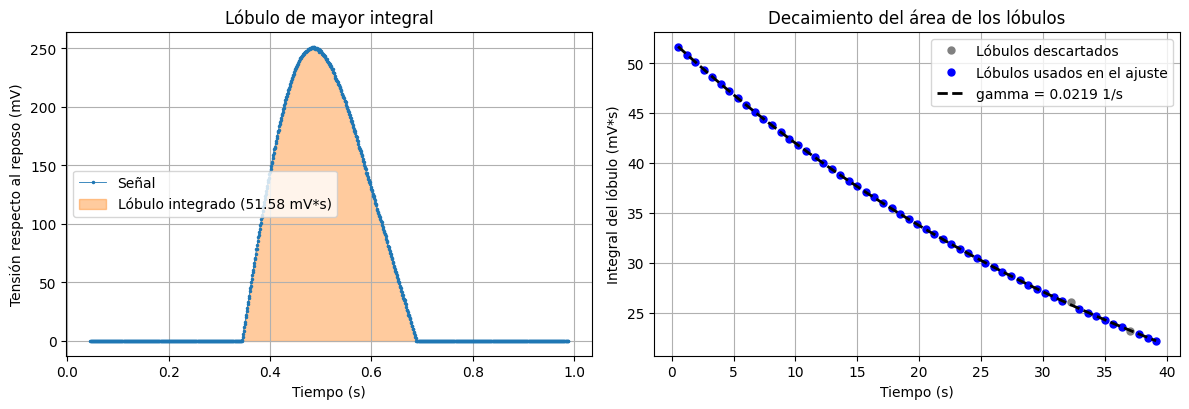

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
margen = 0.3
ventana = (t_sec >= t_pulso[0] - margen) & (t_sec <= t_pulso[-1] + margen)
ax1.plot(t_sec[ventana], v[ventana] * 1e3, ".-", ms=3, lw=0.6, label="Señal")
ax1.fill_between(t_pulso, v_pulso * 1e3, color="tab:orange", alpha=0.4,
                 label=f"Lóbulo integrado ({integral * 1e3:.2f} mV*s)")
ax1.set(xlabel="Tiempo (s)", ylabel="Tensión respecto al reposo (mV)", title="Lóbulo de mayor integral")
ax1.legend()
ax1.grid(True)

tl, al = t_lobulos[usar], abs_areas[usar] * 1e3
ax2.plot(tl[~mask_a], al[~mask_a], "o", color="gray", ms=5, label="Lóbulos descartados")
ax2.plot(tl[mask_a], al[mask_a], "o", color="blue", ms=5, label="Lóbulos usados en el ajuste")
t_curva = np.linspace(tl[mask_a].min(), tl[mask_a].max(), 300)
ax2.plot(t_curva, np.exp(ajuste_a.intercept + ajuste_a.slope * t_curva) * 1e3, "k--", lw=2,
         label=f"gamma = {gamma_a:.4f} 1/s")
ax2.set(xlabel="Tiempo (s)", ylabel="Integral del lóbulo (mV*s)", title="Decaimiento del área de los lóbulos")
ax2.legend(loc="upper right")
ax2.grid(True)
fig.tight_layout()
plt.show()

## 8. Parámetros mecánicos y magnéticos

Con $f_0$, $\gamma$ y la integral de la fem se calculan las magnitudes que dependen de lo que se sepa del montaje:

| Datos que se conocen | Resultado |
|---|---|
| ninguno | $\omega_0$, factor de calidad $Q=\omega_0/(2\gamma)$, decremento logarítmico $2\pi\gamma/\omega_1$, tiempo de decaimiento $1/\gamma$ |
| masa $m$ | $k=m\omega_0^2$ y $b=2m\gamma$ |
| constante $k$ | masa efectiva $k/\omega_0^2$ y $b$ |
| coeficiente $b$ | masa efectiva $b/(2\gamma)$ y $k$ |
| dos o tres entre $m$, $k$, $b$ | comprobación de consistencia con la medición |
| vueltas $N$ | variación de flujo por vuelta $\Delta\Phi$ |
| vueltas $N$ y radio $R$ | campo medio $B$ |

Si se pesa también el resorte, la masa que oscila no es solo la del cuerpo. Para un resorte uniforme de masa $m_r$ y longitud $L$ que se estira linealmente, el elemento a distancia $s$ del extremo fijo se mueve con velocidad $v\,s/L$, y la energía cinética del resorte es $\int_0^L \tfrac{1}{2}\tfrac{m_r}{L}\left(\tfrac{vs}{L}\right)^2 ds = \tfrac{1}{2}\tfrac{m_r}{3}v^2$. El resorte aporta entonces una masa efectiva $m_r/3$, y la masa que oscila es $m + m_r/3$.

In [19]:
def formatear(valor, inc=None, cifras_inc=2):
    """Valor con su incertidumbre redondeada a `cifras_inc` cifras significativas.

    Fuera de [1e-3, 1e5) usa notación científica con el mismo exponente para el valor y la incertidumbre.
    """
    if valor is None or not np.isfinite(valor):
        return "n/d"
    if inc is None or not np.isfinite(inc) or inc <= 0:
        return f"{valor:.4g}"
    exp_inc = math.floor(math.log10(inc)) - (cifras_inc - 1)
    if valor != 0 and (abs(valor) < 1e-3 or abs(valor) >= 1e5):
        e = math.floor(math.log10(abs(valor)))
        dec = max(e - exp_inc, 0)
        return f"({valor / 10 ** e:.{dec}f} +/- {inc / 10 ** e:.{dec}f})e{e:+03d}"
    dec = max(0, -exp_inc)
    return f"{valor:.{dec}f} +/- {inc:.{dec}f}"


def resolver_parametros(medido, montaje):
    """Deduce el resto de magnitudes a partir de lo medido y de los datos del montaje que se conocen.

    Del registro salen f0, gamma y la integral de la fem. El oscilador subamortiguado m x'' + b x' + k x = 0
    cumple gamma = b / (2 m), omega0^2 = k / m y omega1^2 = omega0^2 - gamma^2, donde omega1 = 2 pi f0 es la
    frecuencia angular medida. De los tres parámetros m, k y b basta conocer uno para obtener los otros dos.
    La integral de la fem es N por la variación de flujo; con N y el radio de la bobina se obtiene B.

    Devuelve un diccionario con
        valores : magnitudes calculadas (omega0, Q, k, b, B, ...)
        filas : lista de (clave, nombre, valor, incertidumbre, unidad, origen) para mostrar
        chequeos : comparaciones entre un dato dado y el valor deducido de la medición
        faltantes : qué no se pudo calcular y qué dato hace falta
    """
    f0, gamma = medido["f0_Hz"], medido["gamma_1_s"]
    gamma_err = medido["gamma_err_1_s"]
    integral = medido["integral_emf_Vs"]
    w1 = 2.0 * math.pi * f0
    gamma_pos = gamma > 0
    w0 = math.sqrt(w1 ** 2 + max(gamma, 0.0) ** 2)

    valores = {"omega1_rad_s": w1, "omega0_rad_s": w0}
    filas = [("omega0", "omega0", w0, None, "rad/s", "sqrt(omega1^2 + gamma^2), con omega1 = 2 pi f0")]
    faltantes, chequeos = [], []

    if gamma_pos:
        rel = gamma_err / gamma
        valores.update(Q=w0 / (2 * gamma), decremento_log=2 * math.pi * gamma / w1, tau_amplitud_s=1 / gamma)
        filas += [
            ("Q", "factor de calidad Q", valores["Q"], valores["Q"] * rel, "", "omega0 / (2 gamma)"),
            ("decremento_log", "decremento logarítmico", valores["decremento_log"],
             valores["decremento_log"] * rel, "", "2 pi gamma / omega1"),
            ("tau", "tiempo de decaimiento de la amplitud", valores["tau_amplitud_s"],
             valores["tau_amplitud_s"] * rel, "s", "1 / gamma"),
        ]
    else:
        faltantes.append("Q, b y el tiempo de decaimiento: gamma no es positivo en este registro.")

    # Parámetros mecánicos: basta uno de m, k, b
    m_dada = montaje.masa
    m_ef = None
    if m_dada:
        m_ef = m_dada + (montaje.masa_resorte / 3.0 if montaje.masa_resorte else 0.0)
    k_dada, b_dada = montaje.k, montaje.b

    if m_ef:
        origen_m = "dada" if not montaje.masa_resorte else "masa + masa del resorte / 3"
        filas.append(("masa_ef", "masa efectiva", m_ef, None, "kg", origen_m))
        valores["masa_efectiva_kg"] = m_ef
        valores["k_N_m"] = m_ef * w0 ** 2
        filas.append(("k", "constante del resorte k", valores["k_N_m"], None, "N/m", "m * omega0^2"))
        if gamma_pos:
            valores["b_kg_s"] = 2 * m_ef * gamma
            filas.append(("b", "coeficiente de amortiguamiento b", valores["b_kg_s"],
                          valores["b_kg_s"] * gamma_err / gamma, "kg/s", "2 m gamma"))
    elif k_dada:
        m_calc = k_dada / w0 ** 2
        valores["masa_efectiva_kg"] = m_calc
        filas.append(("masa_ef", "masa efectiva", m_calc, None, "kg", "k / omega0^2"))
        if gamma_pos:
            valores["b_kg_s"] = 2 * m_calc * gamma
            filas.append(("b", "coeficiente de amortiguamiento b", valores["b_kg_s"],
                          valores["b_kg_s"] * gamma_err / gamma, "kg/s", "2 m gamma"))
    elif b_dada and gamma_pos:
        m_calc = b_dada / (2 * gamma)
        valores["masa_efectiva_kg"] = m_calc
        valores["k_N_m"] = m_calc * w0 ** 2
        filas.append(("masa_ef", "masa efectiva", m_calc, m_calc * gamma_err / gamma, "kg", "b / (2 gamma)"))
        filas.append(("k", "constante del resorte k", valores["k_N_m"], valores["k_N_m"] * gamma_err / gamma,
                      "N/m", "m * omega0^2"))
    else:
        faltantes.append("k y b: hace falta la masa que oscila, o k, o b.")

    # Si se conocen dos o más de m, k, b, se comparan con lo medido
    def chequeo(descripcion, dado, deducido):
        dif = (dado - deducido) / deducido
        chequeos.append({"descripcion": descripcion, "dado": dado, "deducido": deducido, "dif_rel": dif,
                         "concuerda": abs(dif) <= TOLERANCIA_CHEQUEO})
    if m_ef and k_dada:
        chequeo("omega0 con los m y k dados frente a omega0 medida (rad/s)", math.sqrt(k_dada / m_ef), w0)
    if m_ef and b_dada and gamma_pos:
        chequeo("gamma = b / (2 m) con los b y m dados frente a gamma medida (1/s)", b_dada / (2 * m_ef), gamma)
    if k_dada and b_dada and gamma_pos:
        chequeo("masa deducida de b frente a la deducida de k (kg)", b_dada / (2 * gamma), k_dada / w0 ** 2)

    # Parte magnética
    filas.append(("integral", "integral de la fem del lóbulo (N * variación de flujo)", integral,
                  medido["sigma_integral_Vs"], "V*s", "medida"))
    N, R = montaje.vueltas, montaje.radio
    if N:
        valores["delta_phi_Wb"] = integral / N
        filas.append(("delta_phi", "variación de flujo por vuelta", integral / N, medido["sigma_integral_Vs"] / N,
                      "Wb", "integral / N"))
    if N and R:
        area = math.pi * R ** 2
        valores["B_T"] = integral / (N * area)
        valores["B_err_T"] = medido["sigma_integral_Vs"] / (N * area)
        filas.append(("B", "campo magnético medio B", valores["B_T"], valores["B_err_T"], "T",
                      "integral / (N pi R^2); la incertidumbre es solo ruido de lectura"))
    elif N:
        faltantes.append("B: hace falta el radio de la bobina.")
    elif R:
        faltantes.append("B: hace falta el número de vueltas de la bobina.")
    else:
        faltantes.append("B: hacen falta el número de vueltas y el radio de la bobina.")
    return {"valores": valores, "filas": filas, "chequeos": chequeos, "faltantes": faltantes}

In [20]:
medido = {"f0_Hz": f0, "gamma_1_s": gamma_a, "gamma_err_1_s": ajuste_a.stderr,
          "integral_emf_Vs": abs(integral), "sigma_integral_Vs": sigma_integral}
res = resolver_parametros(medido, MONTAJE)
print(f"Datos dados: N = {MONTAJE.vueltas:.0f} vueltas, R = {MONTAJE.radio * 1e3:.1f} mm, m = {MONTAJE.masa * 1e3:.0f} g\n")
for clave, nombre, valor, inc, unidad, origen in res["filas"]:
    print(f"{nombre:<52}{formatear(valor, inc):>26} {unidad:<6}{origen}")
print()
for etiqueta, montaje in (("solo la masa", Montaje(masa=0.200)), ("solo k", Montaje(k=16.6)), ("solo b", Montaje(b=0.0088))):
    w = resolver_parametros(medido, montaje)["valores"]
    k_val, b_val = w.get("k_N_m", montaje.k), w.get("b_kg_s", montaje.b)   # El dato dado no se repite en los valores
    print(f"Con {etiqueta:<13} masa efectiva = {w['masa_efectiva_kg'] * 1e3:6.1f} g, k = {k_val:6.2f} N/m, "
          f"b = {b_val:.5f} kg/s")

Datos dados: N = 3400 vueltas, R = 41.5 mm, m = 200 g

omega0                                                                   9.111 rad/s sqrt(omega1^2 + gamma^2), con omega1 = 2 pi f0
factor de calidad Q                                          208.295 +/- 0.068       omega0 / (2 gamma)
decremento logarítmico                                 0.0150825 +/- 0.0000049       2 pi gamma / omega1
tiempo de decaimiento de la amplitud                          45.726 +/- 0.015 s     1 / gamma
masa efectiva                                                              0.2 kg    dada
constante del resorte k                                                   16.6 N/m   m * omega0^2
coeficiente de amortiguamiento b                       0.0087478 +/- 0.0000028 kg/s  2 m gamma
integral de la fem del lóbulo (N * variación de flujo)   0.0515775 +/- 0.0000090 V*s   medida
variación de flujo por vuelta                        (1.51699 +/- 0.00027)e-05 Wb    integral / N
campo magnético medio B           

## 9. Comparación con los valores verdaderos

El registro es simulado, de modo que cada resultado se puede comparar con el valor que se usó para generarlo. Las diferencias de la tabla son las de este análisis con este registro y esta semilla de ruido.

In [21]:
def comparar_con_simulador(medido, resolucion, verdad):
    """Compara lo calculado con los valores verdaderos del simulador. Devuelve lista de (nombre, calculado, verdadero)."""
    v = resolucion["valores"]
    pares = [("f0 (Hz)", medido["f0_Hz"], verdad["f0_Hz"]),
             ("gamma (1/s)", medido["gamma_1_s"], verdad["gamma_1_s"]),
             ("omega0 (rad/s)", v.get("omega0_rad_s"), verdad["omega0_rad_s"]),
             ("Q", v.get("Q"), verdad["Q"]),
             ("k (N/m)", v.get("k_N_m"), verdad["k_N_m"]),
             ("b (kg/s)", v.get("b_kg_s"), verdad["b_kg_s"]),
             ("integral de la fem (V*s)", medido["integral_emf_Vs"], verdad["integral_emf_Vs"]),
             ("B (T)", v.get("B_T"), verdad["B_T"])]
    return [(n, c, t) for n, c, t in pares if c is not None]

In [22]:
comparacion = comparar_con_simulador(medido, res, verdad)
comparacion.insert(2, ("gamma, altura de pulsos (1/s)", gamma_h, verdad["gamma_1_s"]))
print(f"{'magnitud':<32}{'calculado':>14}{'verdadero':>14}{'diferencia':>13}")
for nombre, calculado, verdadero in comparacion:
    print(f"{nombre:<32}{calculado:>14.5g}{verdadero:>14.5g}{100 * (calculado - verdadero) / verdadero:>+11.2f} %")

magnitud                             calculado     verdadero   diferencia
f0 (Hz)                                   1.45          1.45      +0.00 %
gamma (1/s)                            0.02187         0.022      -0.59 %
gamma, altura de pulsos (1/s)          0.02312         0.022      +5.09 %
omega0 (rad/s)                          9.1106        9.1104      +0.00 %
Q                                       208.29        207.06      +0.60 %
k (N/m)                                 16.601          16.6      +0.00 %
b (kg/s)                             0.0087478        0.0088      -0.59 %
integral de la fem (V*s)              0.051578      0.051573      +0.01 %
B (T)                                0.0028037     0.0028035      +0.01 %


## 10. Dónde falla el método

Las secciones anteriores aplican el método a un caso favorable. Aquí se repite el análisis, reunido en una función, con otras geometrías y con un ADC menos ideal.

In [23]:
def analizar_registro(t_sec, voltajes, fs, v_scale, opciones=None):
    """Extrae del registro f0, gamma y la integral de la fem del lóbulo de mayor área.

    `opciones` es una OpcionesAnalisis (por defecto, la validada). Devuelve (medido, series): `medido` es un
    diccionario con números y textos de advertencia, y `series` los arreglos que usan las gráficas.
    """
    opc = opciones or OpcionesAnalisis()
    prep = preparar_senal(t_sec, voltajes, v_scale)
    advertencias = list(prep["advertencias"])
    v, n = prep["v"], len(prep["v"])
    duracion = n / fs

    # 1) Frecuencia dominante
    esp = frecuencia_dominante(prep["proc"], fs, f_min=opc.f_min)
    f0 = esp["f0"]
    if esp["contraste"] < PICO_ESPECTRAL_MIN:
        raise ErrorAnalisis("No se detecta una oscilación clara en el registro (el pico del espectro apenas "
                            f"supera el fondo: contraste {esp['contraste']:.1f}).")
    if duracion * f0 < CICLOS_MINIMOS:
        raise ErrorAnalisis(f"El registro dura {duracion:.1f} s y contiene {duracion * f0:.1f} ciclos; "
                            f"se necesitan al menos {CICLOS_MINIMOS}.")
    if esp["amp_subarmonico"] >= UMBRAL_SUBARMONICO:
        advertencias.append(f"Hay un pico en f0/2 de amplitud {esp['amp_subarmonico']:.2f} veces la de f0: la "
                            "frecuencia de oscilación podría ser la mitad de la detectada.")

    # 2) Decaimiento de la altura de los pulsos
    envelope, env_smooth, indices_picos = envolvente_y_picos(v, f0, fs, opc.kernel_mediano, opc.frac_prominencia)
    ajuste_h = mask_h = None
    if len(indices_picos) >= 3:
        t_picos, A_picos = t_sec[indices_picos], env_smooth[indices_picos]
        ajuste_h, mask_h = ajustar_decaimiento(t_picos, A_picos, opc.umbral_sigma)

    # 3) Lóbulos de la fem: integral de cada uno
    ini, fin, areas = lobulos_de_signo_constante(v, t_sec)
    completos = (ini > 0) & (fin < n - 1)   # Un lóbulo que toca un extremo del registro está cortado
    if not completos.any():
        raise ErrorAnalisis("No hay ningún lóbulo completo en el registro.")
    ini, fin, areas = ini[completos], fin[completos], areas[completos]
    abs_areas = np.abs(areas)
    k_max = int(np.argmax(abs_areas))
    inicio, final = int(ini[k_max]), int(fin[k_max])
    t_pulso, v_pulso = t_sec[inicio:final + 1], v[inicio:final + 1]
    n_lobulo = len(v_pulso)
    if n_lobulo < 10:
        raise ErrorAnalisis(f"El lóbulo de mayor área tiene solo {n_lobulo} muestras: la señal no es fiable.")
    dt = float(np.mean(np.diff(t_pulso)))
    integral = float(trapezoid(v_pulso, t_pulso))   # V*s: N por la variación de flujo, en valor absoluto
    sigma_V = sigma_ruido(v_pulso, v_scale / math.sqrt(12.0))
    sigma_integral = float(sigma_V * math.sqrt(n_lobulo) * dt)   # n muestras independientes con ruido sigma_V
    ancho = float(t_pulso[-1] - t_pulso[0])
    ancho_relativo = ancho * 2.0 * f0   # Cociente entre la duración del lóbulo y medio periodo
    if ancho_relativo < ANCHO_RELATIVO_MIN:
        advertencias.append(
            f"El lóbulo de mayor área dura {100 * ancho_relativo:.0f} % de medio periodo. Si el imán no cruza el "
            "plano de la bobina debería durar casi todo el medio periodo; puede que el ADC no registre la parte "
            "baja de la señal (zona muerta), lo que subestima B y sobrestima gamma. Revisa el rango de tensión "
            "del ADC.")

    # 4) Decaimiento del área de los lóbulos
    usar = abs_areas >= FRAC_AREA_MIN * abs_areas.max()
    ajuste_a = mask_a = None
    t_lobulos = 0.5 * (t_sec[ini] + t_sec[fin])
    if np.count_nonzero(usar) >= MIN_LOBULOS_AREA:
        ajuste_a, mask_a = ajustar_decaimiento(t_lobulos[usar], abs_areas[usar], opc.umbral_sigma)

    if ajuste_a is None and ajuste_h is None:
        raise ErrorAnalisis("No hay suficientes pulsos para ajustar el decaimiento: se necesitan al menos 3 picos "
                            f"(se detectaron {len(indices_picos)}) o {MIN_LOBULOS_AREA} lóbulos.")
    if ajuste_a is not None:
        ajuste, metodo = ajuste_a, "área de los lóbulos"
        n_usados = int(np.count_nonzero(mask_a))
    else:
        ajuste, metodo = ajuste_h, "altura de los pulsos"
        n_usados = int(np.count_nonzero(mask_h))
        advertencias.append(f"Hay menos de {MIN_LOBULOS_AREA} lóbulos completos: gamma se estima solo con la "
                            "altura de los pulsos, que es más sensible a los cambios de forma del pulso.")
    gamma, gamma_err, r2 = -ajuste.slope, ajuste.stderr, ajuste.rvalue ** 2

    if ajuste_a is not None and ajuste_h is not None and gamma > 0 and -ajuste_h.slope > 0:
        cociente = (-ajuste_h.slope) / gamma
        if cociente > 1.0 + UMBRAL_DISCREPANCIA:
            advertencias.append(
                f"La altura de los pulsos decae {100 * (cociente - 1):.0f} % más rápido que su área: la forma de los "
                "pulsos cambia durante el registro (por ejemplo, el imán se acerca menos a la bobina al disminuir la "
                "amplitud). Ambos valores de gamma pueden estar por encima del real. Prueba con una amplitud de "
                "oscilación menor.")
        elif cociente < 1.0 / (1.0 + UMBRAL_DISCREPANCIA):
            advertencias.append(
                f"La altura de los pulsos decae {100 * (1 - cociente):.0f} % más lento que su área. Puede deberse a "
                "que el ADC no registra la parte baja de la señal. Revisa el rango de tensión del ADC.")
    if r2 < 0.95:
        advertencias.append(f"El ajuste exponencial es pobre (R2 = {r2:.3f}): el decaimiento no es exponencial "
                            "limpio o hay interferencias.")
    if gamma <= 0:
        advertencias.append("gamma <= 0: la amplitud no decae en el registro.")
    elif gamma * duracion < 0.1:
        advertencias.append(f"El registro dura {duracion:.0f} s y la amplitud decae solo {100 * (1 - math.exp(-gamma * duracion)):.0f} %: "
                            "gamma tiene mucha incertidumbre. Usa un registro más largo.")

    medido = {
        "n_muestras": n, "fs_Hz": float(fs), "duracion_s": float(duracion), "V_scale_V_per_count": float(v_scale),
        "nivel_reposo_adc": prep["reposo"],
        "f0_Hz": float(f0), "sigma_f_Hz": float(esp["sigma_f"]), "fwhm_Hz": float(esp["fwhm"]),
        "gamma_1_s": float(gamma), "gamma_err_1_s": float(gamma_err), "r2_gamma": float(r2),
        "gamma_metodo": metodo, "gamma_n_usados": n_usados,
        "gamma_altura_1_s": None if ajuste_h is None else float(-ajuste_h.slope),
        "gamma_altura_err_1_s": None if ajuste_h is None else float(ajuste_h.stderr),
        "r2_altura": None if ajuste_h is None else float(ajuste_h.rvalue ** 2),
        "picos_detectados": int(len(indices_picos)),
        "picos_usados": None if mask_h is None else int(np.count_nonzero(mask_h)),
        "gamma_area_1_s": None if ajuste_a is None else float(-ajuste_a.slope),
        "gamma_area_err_1_s": None if ajuste_a is None else float(ajuste_a.stderr),
        "r2_area": None if ajuste_a is None else float(ajuste_a.rvalue ** 2),
        "integral_emf_Vs": abs(integral), "sigma_integral_Vs": sigma_integral,
        "lobulo_t_ini_s": float(t_pulso[0]), "lobulo_t_fin_s": float(t_pulso[-1]), "lobulo_muestras": n_lobulo,
        "lobulo_ancho_relativo": float(ancho_relativo), "adc_negative_clipped": True,
        "advertencias": advertencias,
    }
    series = {
        "t": t_sec, "v": v, "valid": prep["valid"], "n_interpoladas": prep["n_interpoladas"],
        "envelope": envelope, "env_smooth": env_smooth, "indices_picos": indices_picos,
        "ajuste_h": ajuste_h, "mask_h": mask_h,
        "t_lobulos": t_lobulos, "areas_abs": abs_areas, "usar": usar, "ajuste_a": ajuste_a, "mask_a": mask_a,
        "inicio": inicio, "final": final, "integral": integral,
        "freqs": esp["freqs"], "espectro": esp["espectro"], "f_izq": esp["f_izq"], "f_der": esp["f_der"],
    }
    return medido, series

### 10.1 Forma de los pulsos y $\gamma$

$\gamma$ se estima con cómo decae una magnitud de la fem, no la amplitud misma, y eso solo equivale si esa magnitud es proporcional a la amplitud. Para oscilaciones de amplitud $a$ pequeña en torno a la posición de equilibrio $z_0$, el desarrollo del flujo en serie de potencias de la posición da, para la altura máxima de la fem $H$ y para la integral $I$ de un lóbulo,

$$H \approx N\omega a\,|\Phi'|\left[1+\tfrac{1}{2}\left(\tfrac{\Phi''a}{\Phi'}\right)^2\right],\qquad I \approx 2N a\,|\Phi'|\left[1+\tfrac{1}{6}\,\tfrac{\Phi'''a^2}{\Phi'}\right],$$

con las derivadas del flujo evaluadas en $z_0$. Las dos son proporcionales a $a$ salvo por una corrección de orden $a^2$. Si $X = c\,a\,(1+\kappa a^2)$ y $a$ decae como $e^{-\gamma t}$, la tasa de decaimiento de $X$ es $\gamma(1+2\kappa a^2)$. Para la altura, $2\kappa a^2 = (\Phi'' a/\Phi')^2$ es siempre positivo: a este orden, $\gamma$ medida con la altura nunca queda por debajo del valor real. Para el área, el signo depende de $\Phi'''$.

Para el dipolo, $\Phi''/\Phi' = (R^2-4d^2)/[d\,(R^2+d^2)]$, que se anula en $d=R/2$. La figura barre alturas de equilibrio y amplitudes y muestra el cociente entre $\gamma$ estimada y verdadera con cada método.

In [24]:
alturas = (0.030, 0.040, 0.060, 0.080, 0.100)   # Altura del equilibrio sobre la bobina (m)
amplitudes = (0.005, 0.010, 0.020, 0.028)       # Amplitud inicial (m)
barrido = []
for altura in alturas:
    for amplitud in amplitudes:
        t_b, c_b, fs_b, v_b = simular_registro(altura=altura, amplitud=amplitud, n_espurios=0)
        m_b, _ = analizar_registro(t_b, c_b, fs_b, V_SCALE)
        g = v_b["gamma_1_s"]
        barrido.append((altura, amplitud, m_b["gamma_altura_1_s"] / g, m_b["gamma_area_1_s"] / g, m_b["r2_altura"]))
barrido = np.array(barrido)

print(f"{len(barrido)} simulaciones con el mismo oscilador y distinta geometría")
for nombre, col in (("altura de los pulsos", 2), ("área de los lóbulos", 3)):
    sesgo = 100 * (barrido[:, col] - 1)
    print(f"gamma por {nombre:<21} sesgo de {sesgo.min():+.0f} % a {sesgo.max():+.0f} % (media {sesgo.mean():+.0f} %)")
print(f"R2 mínimo del ajuste por altura: {barrido[:, 4].min():.4f}")

20 simulaciones con el mismo oscilador y distinta geometría
gamma por altura de los pulsos  sesgo de +1 % a +38 % (media +12 %)
gamma por área de los lóbulos   sesgo de -21 % a +18 % (media +3 %)
R2 mínimo del ajuste por altura: 0.9934


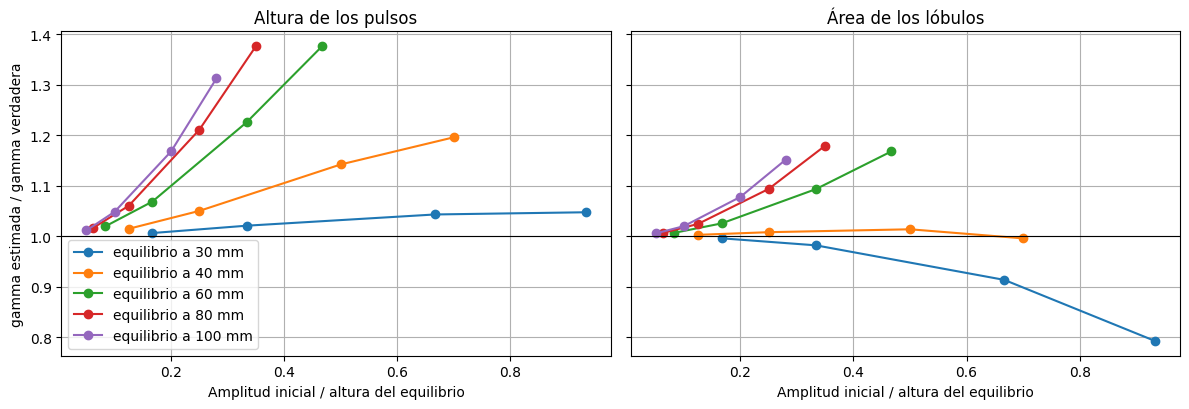

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, titulo in ((ax1, 2, "Altura de los pulsos"), (ax2, 3, "Área de los lóbulos")):
    for altura in alturas:
        filas = barrido[barrido[:, 0] == altura]
        ax.plot(filas[:, 1] / filas[:, 0], filas[:, col], "o-", label=f"equilibrio a {altura * 1e3:.0f} mm")
    ax.axhline(1.0, color="k", lw=0.8)
    ax.set(xlabel="Amplitud inicial / altura del equilibrio", title=titulo)
    ax.grid(True)
ax1.set_ylabel("gamma estimada / gamma verdadera")
ax1.legend()
fig.tight_layout()
plt.show()

La tabla compara el sesgo de $\gamma$ por altura con la predicción de segundo orden, $1+f\,u^2$, donde $u=\Phi'' a/\Phi'$ con la amplitud inicial $a$ y $f$ es el promedio de $e^{-2\gamma t}$ sobre el registro, porque la amplitud decae mientras se mide. Con el equilibrio en $d=R/2$, donde $\Phi''=0$, el sesgo de la altura desaparece, pero el del área no: depende de $\Phi'''$. Lejos de ese punto, la predicción reproduce el sesgo medido con diferencias de poco más de un punto porcentual mientras $|u|$ sea menor que 0.5.

In [26]:
R = MONTAJE.radio
gamma_v = verdad["gamma_1_s"]
T = N / fs
f_prom = (1 - math.exp(-2 * gamma_v * T)) / (2 * gamma_v * T)   # Promedio de exp(-2 gamma t) en el registro
print(f"Promedio de a^2 en el registro: {f_prom:.2f} de su valor inicial")
print("u = Phi'' a / Phi', con la amplitud inicial a; predicción de la altura: 1 + f u^2")
print(f"{'equilibrio':>11}{'amplitud':>10}{'u':>11}{'altura medida':>15}{'altura predicha':>17}{'área medida':>13}")
for altura, amplitud in ((R / 2, 0.004), (R / 2, 0.012), (R / 2, 0.016),
                         (0.060, 0.004), (0.060, 0.008), (0.060, 0.012), (0.060, 0.016)):
    t_b, c_b, fs_b, v_b = simular_registro(altura=altura, amplitud=amplitud, n_espurios=0)
    m_b, _ = analizar_registro(t_b, c_b, fs_b, V_SCALE)
    u = (R ** 2 - 4 * altura ** 2) / (altura * (R ** 2 + altura ** 2)) * amplitud   # Phi'' a / Phi'
    print(f"{altura * 1e3:8.2f} mm{amplitud * 1e3:7.0f} mm{u:11.3f}{m_b['gamma_altura_1_s'] / gamma_v:15.3f}"
          f"{1 + f_prom * u ** 2:17.3f}{m_b['gamma_area_1_s'] / gamma_v:13.3f}")

Promedio de a^2 en el registro: 0.47 de su valor inicial
u = Phi'' a / Phi', con la amplitud inicial a; predicción de la altura: 1 + f u^2
 equilibrio  amplitud          u  altura medida  altura predicha  área medida
   20.75 mm      4 mm      0.000          1.001            1.000        0.991
   20.75 mm     12 mm      0.000          0.995            1.000        0.919
   20.75 mm     16 mm      0.000          0.990            1.000        0.856
   60.00 mm      4 mm     -0.159          1.011            1.012        1.005
   60.00 mm      8 mm     -0.318          1.045            1.047        1.016
   60.00 mm     12 mm     -0.476          1.095            1.107        1.036
   60.00 mm     16 mm     -0.635          1.157            1.190        1.062


### 10.2 Zona muerta del ADC

El ADC del ESP32 es menos preciso con tensiones bajas. Según Espressif, con la atenuación por defecto de Arduino (11 dB) el intervalo de tensión recomendado va de 150 a 2450 mV, y la tensión de referencia varía entre chips (Espressif Systems, s. f.). Con pulsos de 250 mV, una parte de cada lóbulo cae por debajo de 150 mV. El simulador representa el caso extremo con una zona muerta: las tensiones por debajo de un umbral se leen 0 y las demás se desplazan esa cantidad. La tabla y la figura muestran cómo cambian $B$ y $\gamma$ con el umbral, y cuántas advertencias del programa se activan.

In [27]:
zonas = (0.0, 0.010, 0.020, 0.050, 0.100)   # Zona muerta del ADC (V)
dz = []
for zona in zonas:
    t_d, c_d, fs_d, v_d = simular_registro(zona_muerta_V=zona)
    m_d, _ = analizar_registro(t_d, c_d, fs_d, V_SCALE)
    dz.append((zona * 1e3, m_d["integral_emf_Vs"] / v_d["integral_emf_Vs"], m_d["gamma_1_s"] / v_d["gamma_1_s"],
               100 * m_d["lobulo_ancho_relativo"], len(m_d["advertencias"])))
dz = np.array(dz)
print(f"{'zona muerta':>12}{'B / B verdadero':>17}{'gamma / gamma verd.':>21}{'ancho del lóbulo':>18}{'advertencias':>14}")
for zona, b_rel, g_rel, ancho, avisos in dz:
    print(f"{zona:9.0f} mV{b_rel:17.2f}{g_rel:21.2f}{ancho:15.0f} %{avisos:14.0f}")

 zona muerta  B / B verdadero  gamma / gamma verd.  ancho del lóbulo  advertencias
        0 mV             1.00                 0.99             99 %             0
       10 mV             0.93                 1.11             96 %             0
       20 mV             0.87                 1.23             93 %             0
       50 mV             0.69                 1.77             84 %             1
      100 mV             0.43                 3.45             69 %             2


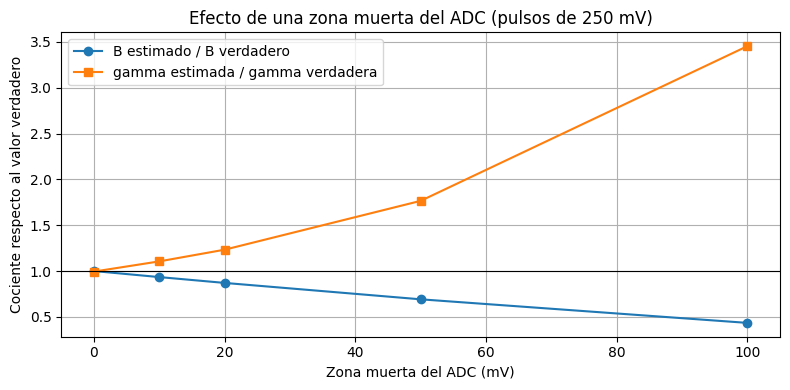

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(dz[:, 0], dz[:, 1], "o-", label="B estimado / B verdadero")
ax.plot(dz[:, 0], dz[:, 2], "s-", label="gamma estimada / gamma verdadera")
ax.axhline(1.0, color="k", lw=0.8)
ax.set(xlabel="Zona muerta del ADC (mV)", ylabel="Cociente respecto al valor verdadero",
       title="Efecto de una zona muerta del ADC (pulsos de 250 mV)")
ax.legend()
ax.grid(True)
fig.tight_layout()
plt.show()

## 11. Resumen de resultados

In [29]:
v_res = res["valores"]
print("RESUMEN (registro simulado de las secciones 2 a 9)")
print(f"  f0 = {formatear(f0, esp['sigma_f'])} Hz")
print(f"  gamma = {formatear(gamma_a, ajuste_a.stderr)} 1/s (área de los lóbulos); "
      f"{formatear(gamma_h, ajuste_h.stderr)} 1/s (altura de los pulsos)")
print(f"  Q = {v_res['Q']:.1f}; tiempo de decaimiento de la amplitud = {v_res['tau_amplitud_s']:.1f} s")
print(f"  k = {v_res['k_N_m']:.4g} N/m; b = {v_res['b_kg_s']:.4g} kg/s")
print(f"  B = {v_res['B_T'] * 1e3:.4g} mT (incertidumbre estadística {v_res['B_err_T'] * 1e3:.1g} mT)")

RESUMEN (registro simulado de las secciones 2 a 9)
  f0 = 1.450 +/- 0.025 Hz
  gamma = 0.0218696 +/- 0.0000071 1/s (área de los lóbulos); 0.023120 +/- 0.000078 1/s (altura de los pulsos)
  Q = 208.3; tiempo de decaimiento de la amplitud = 45.7 s
  k = 16.6 N/m; b = 0.008748 kg/s
  B = 2.804 mT (incertidumbre estadística 0.0005 mT)


## 12. Interpretación y limitaciones

En el registro de las secciones 2 a 9, el análisis recupera $f_0$, $k$ y $B$ con diferencias menores que 0.02 %, y $\gamma$ y $b$ con menos del 1 % cuando $\gamma$ sale del área de los lóbulos; con la altura de los pulsos, $\gamma$ queda un 5 % por encima del valor verdadero. Esas diferencias valen para un registro simulado con un ADC ideal; no son una incertidumbre de una medición real.

La sección 10 identifica dos fuentes de error que el análisis no puede eliminar. La primera es la forma de los pulsos: tanto la altura como el área de los pulsos se desvían de la proporcionalidad con la amplitud a segundo orden, de modo que $\gamma$ queda sesgada cuando la amplitud no es pequeña frente a la escala en la que varía el flujo. A segundo orden, la altura sesga siempre al alza; el área, en uno u otro sentido. Un $R^2$ cercano a 1 no lo delata, pero la discrepancia entre las dos estimaciones sí es una señal de alerta, y reducir la amplitud de oscilación reduce el sesgo.

La segunda es la respuesta del ADC. Una zona muerta de 20 mV, el 8 % del pico, ya desplaza $\gamma$ en un 23 % y $B$ en un 13 % sin que el programa avise; con 50 mV avisa una vez y con 100 mV, dos. La corrección es de hardware: llevar la señal al intervalo recomendado del ADC con un circuito que le sume una tensión continua, lo que además permite digitalizar el lóbulo negativo. El programa admite ese caso sin cambios.

Quedan otras limitaciones. $B$ es un valor medio equivalente con campo uniforme sobre la bobina, y no el campo del imán en un punto; usar el radio externo de la bobina como radio de cada vuelta sobrestima el área y sesga $B$ a la baja. $k$ y $b$ son proporcionales a la masa dada. Por último, el método se validó solo con registros simulados: no se ha contrastado con mediciones nuevas ni con el ESP32 conectado.


## Referencias

Espressif Systems. (s. f.). *Analog to digital converter (ADC)*. ESP-IDF Programming Guide, release v4.4 (ESP32). https://docs.espressif.com/projects/esp-idf/en/release-v4.4/api-reference/peripherals/adc.html

Griffiths, D. J. (2017). *Introduction to electrodynamics* (4.ª ed.). Cambridge University Press.

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., . . . Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*(7825), 357–362. https://doi.org/10.1038/s41586-020-2649-2

Harris, F. J. (1978). On the use of windows for harmonic analysis with the discrete Fourier transform. *Proceedings of the IEEE, 66*(1), 51–83. https://doi.org/10.1109/PROC.1978.10837

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55

Marple, S. L., Jr. (1999). Computing the discrete-time "analytic" signal via FFT. *IEEE Transactions on Signal Processing, 47*(9), 2600–2603.

Taylor, J. R. (2005). *Classical mechanics*. University Science Books.

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., . . . SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2